# 5. Regimes de cultivo

> **Os dados deste projeto são SIMULADOS** (ver notebook 01). As simulações são previsões do modelo; os valores da tabela 5.1 vêm da literatura.

O crescimento não depende só do peso e da temperatura: depende também do **regime de cultivo**. Neste notebook comparamos:

| Regime | Ideia principal |
|---|---|
| **Extensivo** | Peixes em lagoas costeiras, sem ração, a comer alimento natural. Densidades muito baixas. |
| **Semi-intensivo** | Lagoas ou tanques de terra, com alimento natural e alguma ração. |
| **Intensivo em jaulas no mar** (sistema aberto) | Ração, densidades médias; a água e a temperatura são as do mar. |
| **Intensivo em tanques em terra / RAS** | Ração, densidades altas. Num **RAS** (*recirculating aquaculture system*) a água é tratada e reutilizada, o que permite **controlar a temperatura**. |
| **IMTA** (*integrated multi-trophic aquaculture*) | Os peixes são cultivados junto com espécies que aproveitam os seus resíduos (bivalves, pepinos-do-mar, algas). |

**Regra deste notebook:** só simulamos os efeitos para os quais encontrámos uma fonte. Onde não há dados fiáveis, dizemo-lo.

In [1]:
import sys
sys.path.append("..")   # para o Python encontrar a pasta src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.growth import PARAMETROS, simular_ciclo, dias_ate_peso
from src.regimes import (TABELA_REGIMES, MESES_FAO_JAULA, MESES_FAO_TANQUE, MESES_FAO_EXTENSIVO,
                         TEMPERATURA_TANQUE, fator_crescimento_densidade, FATOR_FCR_IMTA)

sns.set_theme(style="whitegrid", context="notebook")
CORES = {"dourada": "#c9971c", "robalo": "#3f6ea6"}
NOMES = {"dourada": "Dourada (Sparus aurata)", "robalo": "Robalo (Dicentrarchus labrax)"}
ESPECIES = ["dourada", "robalo"]
N_DIAS, N_PEIXES = 900, 5000

## 5.1 O que diz a literatura (dourada)

Valores da ficha da FAO para a dourada (FAO, 2009; texto de Colloca & Cerasi). "sem dados fiáveis" quer dizer que **não encontrámos** esse valor numa fonte fiável.

In [2]:
TABELA_REGIMES.fillna("sem dados fiáveis").set_index("regime")

,alimentação,densidade (kg/m³),produção (kg/ha/ano),tempo até ao tamanho comercial,FCR,controlo da temperatura
regime,,,,,,
Extensivo (lagoas),alimento natural,"≤ 0,0025",15–30,20 meses até 350 g (juvenis de 2–3 g),— (sem ração),não
Semi-intensivo (lagoas e tanques de terra),natural + ração,≤ 1,500–2 400,sem dados fiáveis,sem dados fiáveis,não
Intensivo: jaulas no mar,ração,10–15,sem dados fiáveis,≈ 16 meses até 350–400 g (juvenis de 5 g),sem dados fiáveis,não
Intensivo: tanques em terra,ração,15–45,sem dados fiáveis,"≈ 12 meses até 350–400 g (juvenis de 5 g, 18–2...","≈ 1,3",sim


**Leitura:**
- Do extensivo para o intensivo, a densidade aumenta mais de **10 000 vezes** (de 0,0025 para 15–45 kg/m³) e o tempo até ao tamanho comercial diminui de 20 para cerca de 12 meses.
- No **extensivo** não há ração (e por isso não há FCR): os peixes crescem com o alimento natural da lagoa. O nosso modelo de crescimento foi ajustado a peixes alimentados com ração, por isso **não o usamos para o extensivo nem para o semi-intensivo**.
- Para o **robalo** não encontrámos uma tabela equivalente.

**Outros dados que não encontrámos:** crescimento e FCR em tanques de terra em Portugal; efeito do IMTA na dourada (só encontrámos uma citação secundária, que não conseguimos verificar).

## 5.2 Jaula no mar vs. tanque com temperatura controlada

A grande diferença entre uma jaula e um tanque em terra (ou RAS) é a **temperatura**:
- **Jaula:** a temperatura é a do mar (usamos a curva sazonal do notebook 01, 15–23 °C, com entrada a 1 de abril).
- **Tanque / RAS:** a temperatura é controlada. Usamos **22 °C constantes** (pressuposto: o meio do intervalo 18–26 °C indicado pela FAO).

Para comparar com a FAO, começamos com juvenis de **5 g** e medimos o tempo até 350 e 400 g.

In [3]:
simulacoes = {}
linhas = []
for especie in ESPECIES:
    jaula = simular_ciclo(especie, N_DIAS, N_PEIXES, peso_inicial_g=5, semente=42)
    tanque = simular_ciclo(especie, N_DIAS, N_PEIXES, peso_inicial_g=5,
                           temperatura=np.full(N_DIAS, TEMPERATURA_TANQUE), semente=42)
    simulacoes[(especie, "jaula")] = jaula
    simulacoes[(especie, "tanque")] = tanque
    for regime, sim in [("jaula no mar", jaula), (f"tanque a {TEMPERATURA_TANQUE:g} °C", tanque)]:
        linhas.append({"espécie": especie, "regime": regime,
                       "meses até 350 g": round(dias_ate_peso(sim, 350) / 30.4, 1),
                       "meses até 400 g": round(dias_ate_peso(sim, 400) / 30.4, 1)})
jaula_tanque = pd.DataFrame(linhas).set_index(["espécie", "regime"])
jaula_tanque

meses até 350 g  meses até 400 g
espécie regime                                          
dourada jaula no mar               16.0             16.9
        tanque a 22 °C             11.6             12.5
robalo  jaula no mar               17.7             18.6
        tanque a 22 °C             13.4             14.2

**Validação com a FAO (dourada, juvenis de 5 g até 350–400 g):**

| | Simulação | FAO (2009) |
|---|---|---|
| Tanque (18–26 °C) | 11,6–12,5 meses | ≈ 12 meses ✅ |
| Jaula no mar | 16,0–16,9 meses | ≈ 16 meses ✅ |

As duas coincidem com a FAO. Com o modelo de crescimento anterior (Lupatsch et al., 2003) a jaula saía cerca de 2 meses mais rápida do que a FAO; com o modelo TGC de Mayer et al. (2012), ajustado a jaulas comerciais, a diferença desapareceu. É uma validação independente: a FAO não foi usada para ajustar o modelo.

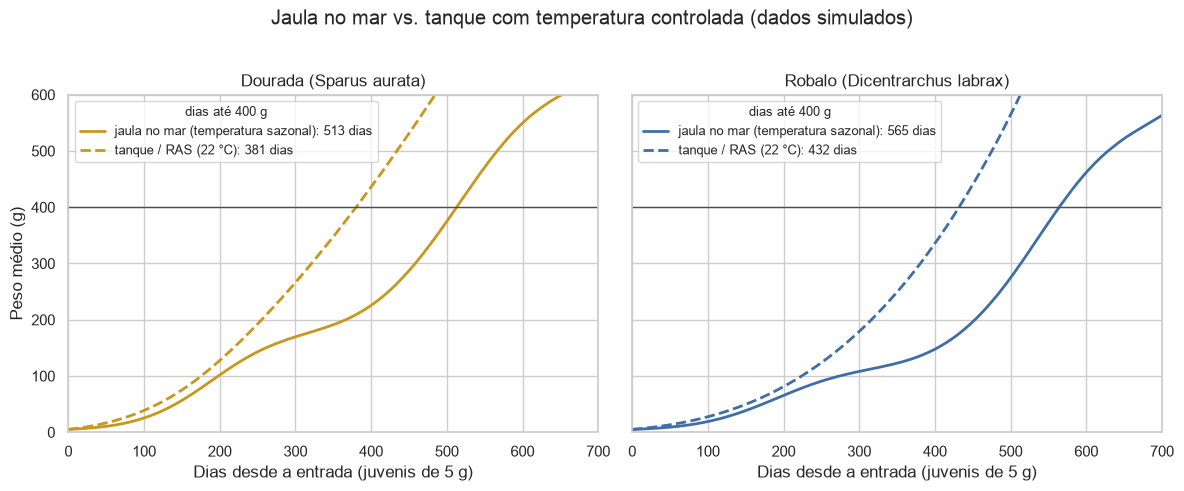

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, especie in zip(axes, ESPECIES):
    for regime, estilo, nome in [("jaula", "-", "jaula no mar (temperatura sazonal)"),
                                 ("tanque", "--", f"tanque / RAS ({TEMPERATURA_TANQUE:g} °C)")]:
        sim = simulacoes[(especie, regime)]
        ax.plot(sim["dia"], sim["peso_medio_g"], color=CORES[especie], linestyle=estilo, linewidth=2,
                label=f"{nome}: {dias_ate_peso(sim, 400)} dias")
    ax.axhline(400, color="0.3", linewidth=1)
    ax.set_xlim(0, 700)
    ax.set_ylim(0, 600)
    ax.set_title(NOMES[especie])
    ax.set_xlabel("Dias desde a entrada (juvenis de 5 g)")
    ax.legend(title="dias até 400 g", fontsize=9, title_fontsize=9, loc="upper left")
axes[0].set_ylabel("Peso médio (g)")
fig.suptitle("Jaula no mar vs. tanque com temperatura controlada (dados simulados)", y=1.02)
plt.tight_layout()
plt.show()

No tanque a temperatura constante evita a **paragem do inverno**: as duas espécies chegam aos 400 g cerca de **4 a 4,5 meses mais cedo** do que na jaula. Em troca, um tanque ou RAS tem custos muito mais altos (construção, bombagem, aquecimento ou arrefecimento da água, oxigénio).

## 5.3 RAS: até que densidade se pode ir? (robalo)

Num RAS o espaço é caro, por isso interessa usar densidades altas. Sammouth et al. (2009) criaram robalos num RAS a 10, 40, 70 e 100 kg/m³ e verificaram que:
- **até 70 kg/m³** não havia diferenças na SGR, no FCR nem na mortalidade;
- **a 100 kg/m³** a SGR descia **14 %**.

Simulamos o robalo num RAS a 22 °C com estas densidades. **Simplificação:** aplicamos o efeito da densidade durante todo o ciclo, como se a densidade se mantivesse constante (numa exploração, os peixes são separados por tanques à medida que crescem).

In [5]:
linhas = []
sims_densidade = {}
for densidade in [40, 70, 100]:
    fator = fator_crescimento_densidade(densidade)
    sim = simular_ciclo("robalo", N_DIAS, N_PEIXES, temperatura=np.full(N_DIAS, TEMPERATURA_TANQUE),
                        fator_crescimento=fator, semente=42)
    sims_densidade[densidade] = sim
    dia = dias_ate_peso(sim, 400)
    biomassa = sim.loc[dia, "biomassa_kg"]
    linhas.append({"densidade (kg/m³)": densidade,
                   "fator de crescimento": round(fator, 2),
                   "dias até 400 g": dia,
                   "biomassa aos 400 g (kg)": round(biomassa),
                   "volume de tanque necessário (m³)": round(biomassa / densidade, 1)})
densidade_ras = pd.DataFrame(linhas).set_index("densidade (kg/m³)")
densidade_ras

,fator de crescimento,dias até 400 g,biomassa aos 400 g (kg),volume de tanque necessário (m³)
densidade (kg/m³),,,,
40,1.00,452,1731,43.3
70,1.00,452,1731,24.7
100,0.86,526,1694,16.9


**Leitura:**
- Passar de 40 para 70 kg/m³ **não atrasa** o crescimento e reduz o volume de tanque necessário em cerca de 40 %.
- Passar de 70 para 100 kg/m³ poupa mais 30 % de volume, mas o ciclo fica **cerca de 2,5 meses mais longo** (74 dias).
- Com estes dados, **70 kg/m³** é o melhor compromisso. Sammouth et al. (2009) só testaram 63 dias com peixes de 135 g; densidades altas durante um ciclo inteiro podem ter efeitos (bem-estar, doenças) que este estudo não mediu.

## 5.4 IMTA: aproveitar os resíduos (robalo)

Num sistema IMTA, os bivalves filtram a matéria orgânica e o fitoplâncton e os pepinos-do-mar comem os resíduos que se depositam no fundo. Cotou et al. (2024) compararam robalos em monocultura com robalos em IMTA (com mexilhões, ostras e pepinos-do-mar) durante 90 dias:

| | Monocultura | IMTA | Diferença significativa? |
|---|---|---|---|
| SGR (%/dia) | 0,58 | 0,68 | não (p = 0,20) |
| Sobrevivência (%) | 91,9 | 98,2 | não (p = 0,14) |
| FCR | 1,66 | 1,47 | **sim** (p = 0,002) |

Como só o FCR foi significativamente diferente, simulamos o IMTA com o **FCR × 0,89** e o crescimento e a mortalidade iguais. É um **ensaio piloto** curto e em pequena escala; aplicá-lo a um ciclo inteiro em jaula é uma extrapolação.

In [6]:
base = simular_ciclo("robalo", N_DIAS, N_PEIXES, semente=42)
imta = simular_ciclo("robalo", N_DIAS, N_PEIXES, fcr=PARAMETROS["robalo"]["fcr"] * FATOR_FCR_IMTA, semente=42)

linhas = []
for regime, sim in [("monocultura em jaula", base), ("IMTA", imta)]:
    dia = dias_ate_peso(sim, 400)
    ate_400 = sim.loc[:dia]
    racao = ate_400["racao_kg"].sum()
    ganho = ate_400["biomassa_kg"].iloc[-1] - N_PEIXES * 3 / 1000
    linhas.append({"regime": regime, "dias até 400 g": dia, "ração total (kg)": round(racao),
                   "FCR económico": round(racao / ganho, 2)})
imta_tabela = pd.DataFrame(linhas).set_index("regime")
poupanca = 1 - imta_tabela.loc["IMTA", "ração total (kg)"] / imta_tabela.loc["monocultura em jaula", "ração total (kg)"]
print(f"Ração poupada com IMTA: {poupanca:.0%}")
imta_tabela

Ração poupada com IMTA: 11%


,dias até 400 g,ração total (kg),FCR económico
regime,,,
monocultura em jaula,590,3813,2.31
IMTA,590,3394,2.06


Com o mesmo crescimento, o IMTA poupa cerca de **11 % da ração** por ciclo. Além disso (e é esse o objetivo principal do IMTA), produz bivalves e pepinos-do-mar que podem ser vendidos e reduz a carga de nutrientes no ambiente, benefícios que o nosso modelo não contabiliza.

## 5.5 Resumo: tempo até ao tamanho comercial em cada regime (dourada)

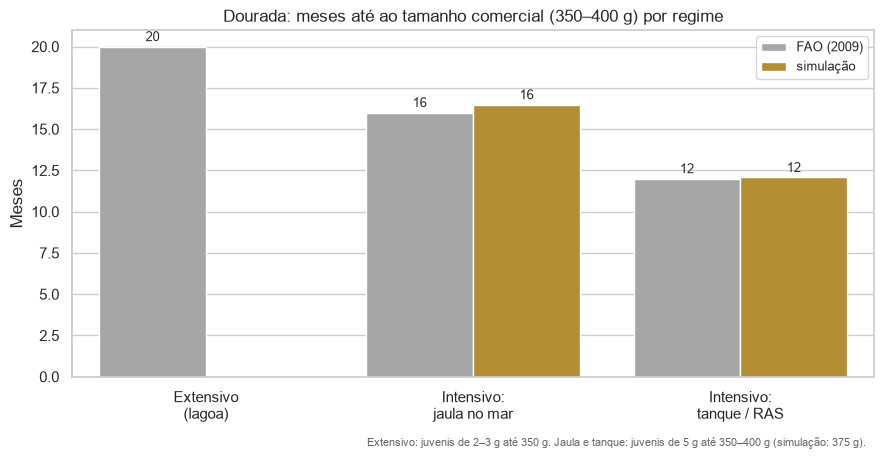

In [7]:
dourada_jaula = simulacoes[("dourada", "jaula")]
dourada_tanque = simulacoes[("dourada", "tanque")]
resumo = pd.DataFrame([
    {"regime": "Extensivo\n(lagoa)", "fonte": "FAO (2009)", "meses": MESES_FAO_EXTENSIVO},
    {"regime": "Intensivo:\njaula no mar", "fonte": "FAO (2009)", "meses": MESES_FAO_JAULA},
    {"regime": "Intensivo:\njaula no mar", "fonte": "simulação", "meses": dias_ate_peso(dourada_jaula, 375) / 30.4},
    {"regime": "Intensivo:\ntanque / RAS", "fonte": "FAO (2009)", "meses": MESES_FAO_TANQUE},
    {"regime": "Intensivo:\ntanque / RAS", "fonte": "simulação", "meses": dias_ate_peso(dourada_tanque, 375) / 30.4},
])

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(data=resumo, x="regime", y="meses", hue="fonte",
            palette={"FAO (2009)": "0.65", "simulação": CORES["dourada"]}, ax=ax)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", padding=2, fontsize=9)
ax.set_title("Dourada: meses até ao tamanho comercial (350–400 g) por regime")
ax.set_xlabel("")
ax.set_ylabel("Meses")
ax.legend(title="", fontsize=9)
ax.text(0.99, -0.2, "Extensivo: juvenis de 2–3 g até 350 g. Jaula e tanque: juvenis de 5 g até 350–400 g (simulação: 375 g).",
        transform=ax.transAxes, ha="right", fontsize=8, color="0.4")
plt.tight_layout()
plt.savefig("../figures/05_regimes.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.6 Conclusões

1. **Intensificar encurta o ciclo:** da lagoa extensiva (20 meses) para o tanque com temperatura controlada (≈ 12 meses), segundo a FAO. A simulação reproduz a FAO tanto na jaula (≈ 16 meses) como no tanque (≈ 12 meses).
2. **Controlar a temperatura** (tanque / RAS) poupa cerca de 4 a 4,5 meses por ciclo nas duas espécies, porque elimina a paragem de crescimento no inverno.
3. **Num RAS, o robalo aguenta até 70 kg/m³** sem perder crescimento; a 100 kg/m³ o ciclo fica cerca de 2,5 meses mais longo (Sammouth et al., 2009).
4. **O IMTA reduz o FCR do robalo em cerca de 11 %** sem alterar o crescimento (Cotou et al., 2024, ensaio piloto).
5. **Faltam dados** para simular o extensivo e o semi-intensivo (o modelo assume alimentação com ração), para o IMTA com dourada e para tanques de terra em Portugal.

**Limitações:** temperatura do tanque (22 °C) e curva sazonal do mar são pressupostos; o TGC do robalo é uma calibração; efeitos de densidade e IMTA vêm de ensaios curtos com robalo e foram extrapolados para um ciclo inteiro; não incluímos bem-estar animal nem impacto ambiental (os custos estão na app).